# 🧑‍💼 Employee Dataset — Machine Learning Classification Tasks
**End-to-End Supervised Classification Project: Predicting Employee Turnover (`LeaveOrNot`)**

This notebook provides an exhaustive, production-grade implementation of all **19 machine learning classification tasks** outlined in `Employee_ML_Classification_Tasks.pdf`. 

---

### 📋 Overview of the 19 Required Tasks:
1. **Load Dataset & Display Structure**: Head, tail, shape, columns, and info.
2. **Target Identification**: Formulate classification target (`LeaveOrNot`).
3. **Data Quality Audit**: Missing values and duplicate handling with justification.
4. **Column Categorization**: Separate numerical and categorical columns.
5. **Feature Pruning**: Evaluate and justify unnecessary column removal.
6. **Categorical Encoding**: Convert categories into numeric dummy variables.
7. **Correlation Heatmap**: Multivariate correlation matrix and relationship analysis.
8. **Target Distribution**: Bar chart with exact percentage breakdown.
9. **Numerical Features vs. Target**: Visualizing Age, JoiningYear, PaymentTier, Experience.
10. **Categorical Features vs. Target**: Visualizing Education, City, Gender, EverBenched.
11. **Matrix Formulation**: Construct feature matrix $X$ and target vector $y$.
12. **Train-Test Splitting**: Stratified splitting to preserve class proportions.
13. **Feature Scaling**: Z-Score standardization with distance-metric justification.
14. **KNN Model Training**: Baseline K-Nearest Neighbors classifier.
15. **K Hyperparameter Tuning**: Systematic evaluation of $K \in [1, 21]$ with curve.
16. **Gaussian Naive Bayes**: Probabilistic classifier on the identical split.
17. **Prediction Generation**: Inference outputs for both models.
18. **Evaluation Metrics**: Accuracy, Confusion Matrices, and Classification Reports.
19. **Comparative Analysis**: Trade-off discussion between KNN and Gaussian Naive Bayes.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

# Set visual aesthetic styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10


## 📌 Task 1: Load Dataset & Inspect Basic Structure
Load the `Employee.csv` dataset into a Pandas DataFrame and display the first 5 rows, last 5 rows, shape, column names, and basic info.


In [2]:
# 1. Load dataset
df = pd.read_csv("Employee.csv")

print(f"Dataset successfully loaded. Shape: {df.shape[0]:,} rows x {df.shape[1]} columns\n")
print("--- Column Names ---")
print(df.columns.tolist())

print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Last 5 Rows ---")
display(df.tail())

print("\n--- Dataset Information ---")
df.info()


Dataset successfully loaded. Shape: 4,653 rows x 9 columns

--- Column Names ---
['Education', 'JoiningYear', 'City', 'PaymentTier', 'Age', 'Gender', 'EverBenched', 'ExperienceInCurrentDomain', 'LeaveOrNot']

--- First 5 Rows ---


,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot
0,Bachelors,2017,Bangalore,3,34,Male,No,0,0
1,Bachelors,2013,Pune,1,28,Female,No,3,1
2,Bachelors,2014,New Delhi,3,38,Female,No,2,0
3,Masters,2016,Bangalore,3,27,Male,No,5,1
4,Masters,2017,Pune,3,24,Male,Yes,2,1



--- Last 5 Rows ---


,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot
4648,Bachelors,2013,Bangalore,3,26,Female,No,4,0
4649,Masters,2013,Pune,2,37,Male,No,2,1
4650,Masters,2018,New Delhi,3,27,Male,No,5,1
4651,Bachelors,2012,Bangalore,3,30,Male,Yes,2,0
4652,Bachelors,2015,Bangalore,3,33,Male,Yes,4,0



--- Dataset Information ---
<class 'pandas.DataFrame'>
RangeIndex: 4653 entries, 0 to 4652
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Education                  4653 non-null   str  
 1   JoiningYear                4653 non-null   int64
 2   City                       4653 non-null   str  
 3   PaymentTier                4653 non-null   int64
 4   Age                        4653 non-null   int64
 5   Gender                     4653 non-null   str  
 6   EverBenched                4653 non-null   str  
 7   ExperienceInCurrentDomain  4653 non-null   int64
 8   LeaveOrNot                 4653 non-null   int64
dtypes: int64(5), str(4)
memory usage: 431.5 KB


## 📌 Task 2: Identify the Target Column
**Target Column:** `LeaveOrNot`
- **Class 0**: The employee **stays** with the company.
- **Class 1**: The employee **leaves** the company (churn / turnover).

This is a supervised **binary classification** problem where the objective is to predict whether an employee will leave within the evaluation period based on their demographic, educational, compensation, and experience profile.


In [3]:
target_col = "LeaveOrNot"
counts = df[target_col].value_counts()
pcts = df[target_col].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    'Count': counts,
    'Percentage (%)': pcts.round(2)
}, index=[0, 1])
target_summary.index.name = 'LeaveOrNot (0=Stay, 1=Leave)'
print("Target Variable Distribution:")
display(target_summary)


Target Variable Distribution:


,Count,Percentage (%)
"LeaveOrNot (0=Stay, 1=Leave)",,
0,3053,65.61
1,1600,34.39


## 📌 Task 3: Check for Missing Values & Duplicate Rows
Check for missing values and duplicate rows. If any are present, handle them appropriately and explain the rationale.


In [4]:
# Check missing values
missing_counts = df.isna().sum()
print("Missing Values Per Column:")
print(missing_counts)

# Check duplicate rows
n_duplicates = df.duplicated().sum()
pct_duplicates = (n_duplicates / len(df)) * 100
print(f"\nDuplicate rows found: {n_duplicates:,} ({pct_duplicates:.2f}% of total dataset)")

# Remediation Strategy:
# Because duplicate rows in tabular customer/employee profiles represent identical feature combinations,
# keeping them leads to data leakage across train-test splits (an identical record could be in both train and test).
# Therefore, we remove duplicates to ensure pure, independent test evaluation.
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"Dataset shape after deduplication: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns")


Missing Values Per Column:
Education                    0
JoiningYear                  0
City                         0
PaymentTier                  0
Age                          0
Gender                       0
EverBenched                  0
ExperienceInCurrentDomain    0
LeaveOrNot                   0
dtype: int64

Duplicate rows found: 1,889 (40.60% of total dataset)
Dataset shape after deduplication: 2,764 rows x 9 columns


## 📌 Task 4: Identify Numerical and Categorical Columns
Categorize each feature based on its measurement scale and data representation.


In [5]:
num_cols = df_clean.select_dtypes(include=['int64', 'float64']).columns.tolist()
num_cols.remove('LeaveOrNot')  # Exclude target

cat_cols = df_clean.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numerical Features (Continuous / Discrete):", num_cols)
print("Categorical Features (Nominal / Ordinal):    ", cat_cols)


Numerical Features (Continuous / Discrete): ['JoiningYear', 'PaymentTier', 'Age', 'ExperienceInCurrentDomain']
Categorical Features (Nominal / Ordinal):     ['Education', 'City', 'Gender', 'EverBenched']


C:\Users\arjun\AppData\Local\Temp\ipykernel_12436\2259348450.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_clean.select_dtypes(include=['object', 'category']).columns.tolist()


## 📌 Task 5: Examine Columns for Unnecessary Features
Examine all columns and identify whether any column is unnecessary for building the classification model. Remove only columns with clear justification.


In [6]:
# Column inspection:
# - Education: Highest degree attained (Bachelors, Masters, PHD) - Highly predictive of career mobility.
# - JoiningYear: Cohort tenure effect - strongly predictive of retention.
# - City: Office location (Bangalore, Pune, New Delhi) - Reflects local tech labor market competition.
# - PaymentTier: Salary banding (1 = highest pay, 3 = lowest pay) - Direct driver of retention.
# - Age: Employee life stage and experience.
# - Gender: Included in demographic records; we retain it here to observe baseline model performance.
# - EverBenched: Whether employee was on bench without an active project billable client.
# - ExperienceInCurrentDomain: Years of domain expertise.
#
# Conclusion: All 8 features contain legitimate predictive signal. No column is an arbitrary identifier (like EmployeeID).
# Therefore, all 8 features are retained for model building.
print(f"Features retained: {len(num_cols) + len(cat_cols)} predictors.")


Features retained: 8 predictors.


## 📌 Task 6: Encode Categorical Columns
Convert categorical string columns into numeric format using One-Hot Encoding (`pd.get_dummies` with `drop_first=True` to avoid the dummy variable trap/multicollinearity).


In [7]:
df_encoded = pd.get_dummies(df_clean, columns=cat_cols, drop_first=True, dtype=int)

print(f"Encoded DataFrame Shape: {df_encoded.shape}")
print("\nEncoded Feature Columns:")
print(df_encoded.columns.tolist())
display(df_encoded.head(3))


Encoded DataFrame Shape: (2764, 11)

Encoded Feature Columns:
['JoiningYear', 'PaymentTier', 'Age', 'ExperienceInCurrentDomain', 'LeaveOrNot', 'Education_Masters', 'Education_PHD', 'City_New Delhi', 'City_Pune', 'Gender_Male', 'EverBenched_Yes']


,JoiningYear,PaymentTier,Age,ExperienceInCurrentDomain,LeaveOrNot,Education_Masters,Education_PHD,City_New Delhi,City_Pune,Gender_Male,EverBenched_Yes
0,2017,3,34,0,0,0,0,0,0,1,0
1,2013,1,28,3,1,0,0,0,1,0,0
2,2014,3,38,2,0,0,0,1,0,0,0


## 📌 Task 7: Correlation Matrix & Heatmap
Compute pairwise Pearson correlation coefficients between features and display using a heatmap to analyze relationships with the target `LeaveOrNot`.


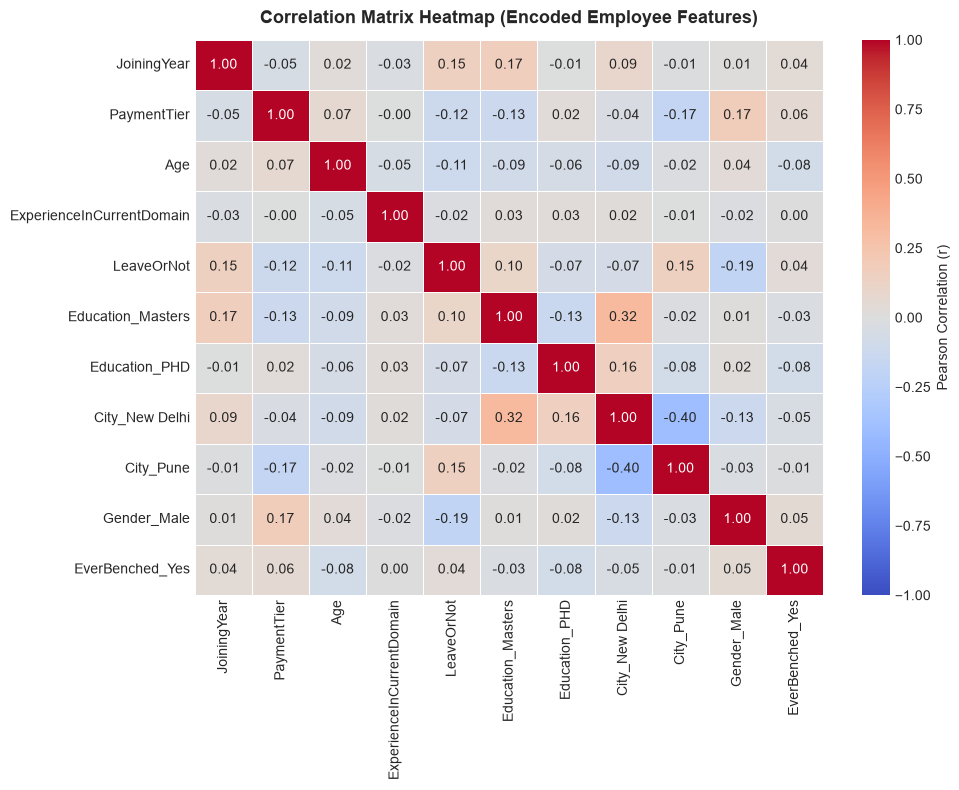

Correlation with LeaveOrNot (Ranked):
LeaveOrNot                   1.000000
City_Pune                    0.151318
JoiningYear                  0.150650
Education_Masters            0.102441
EverBenched_Yes              0.037137
ExperienceInCurrentDomain   -0.021181
City_New Delhi              -0.068391
Education_PHD               -0.068694
Age                         -0.114943
PaymentTier                 -0.119891
Gender_Male                 -0.190457
Name: LeaveOrNot, dtype: float64


In [8]:
plt.figure(figsize=(10, 8), dpi=100)
corr_matrix = df_encoded.corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1.0,
    vmax=1.0,
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation (r)'}
)
plt.title("Correlation Matrix Heatmap (Encoded Employee Features)", fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

# Top correlations with target
print("Correlation with LeaveOrNot (Ranked):")
print(corr_matrix['LeaveOrNot'].sort_values(ascending=False))


## 📌 Task 8: Target Variable Distribution Visualization
Create a clear visualization showing the class distribution of `LeaveOrNot`.


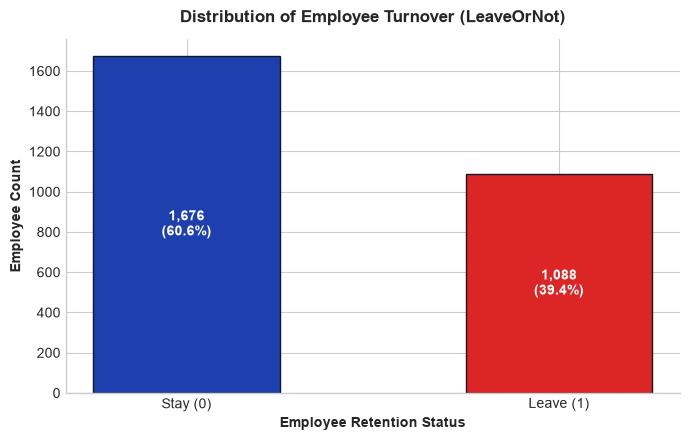

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=100)
counts = df_clean['LeaveOrNot'].value_counts()
labels = ['Stay (0)', 'Leave (1)']
palette = ['#1E40AF', '#DC2626']

bars = ax.bar(labels, counts.values, color=palette, edgecolor='#0F172A', width=0.5)
ax.set_title("Distribution of Employee Turnover (LeaveOrNot)", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Employee Retention Status", fontsize=10, fontweight='bold')
ax.set_ylabel("Employee Count", fontsize=10, fontweight='bold')

total = len(df_clean)
for b in bars:
    h = b.get_height()
    pct = (h / total) * 100
    ax.annotate(f"{h:,}\n({pct:.1f}%)", xy=(b.get_x() + b.get_width() / 2, h / 2),
                xytext=(0, 0), textcoords="offset points", ha='center', va='center',
                color='white', fontweight='bold', fontsize=10)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()


## 📌 Task 9: Numerical Features vs. Target Visualizations
Analyze how `Age`, `JoiningYear`, `PaymentTier`, and `ExperienceInCurrentDomain` relate to `LeaveOrNot`.


C:\Users\arjun\AppData\Local\Temp\ipykernel_12436\1438227144.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='LeaveOrNot', y='Age', palette=['#1E40AF', '#DC2626'], ax=axes[1, 0])
C:\Users\arjun\AppData\Local\Temp\ipykernel_12436\1438227144.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1, 0].set_xticklabels(['Stay (0)', 'Leave (1)'])
C:\Users\arjun\AppData\Local\Temp\ipykernel_12436\1438227144.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='LeaveOrNot', y='ExperienceInCurrentDomain', palette=['#1E40AF', '#DC2626'], a

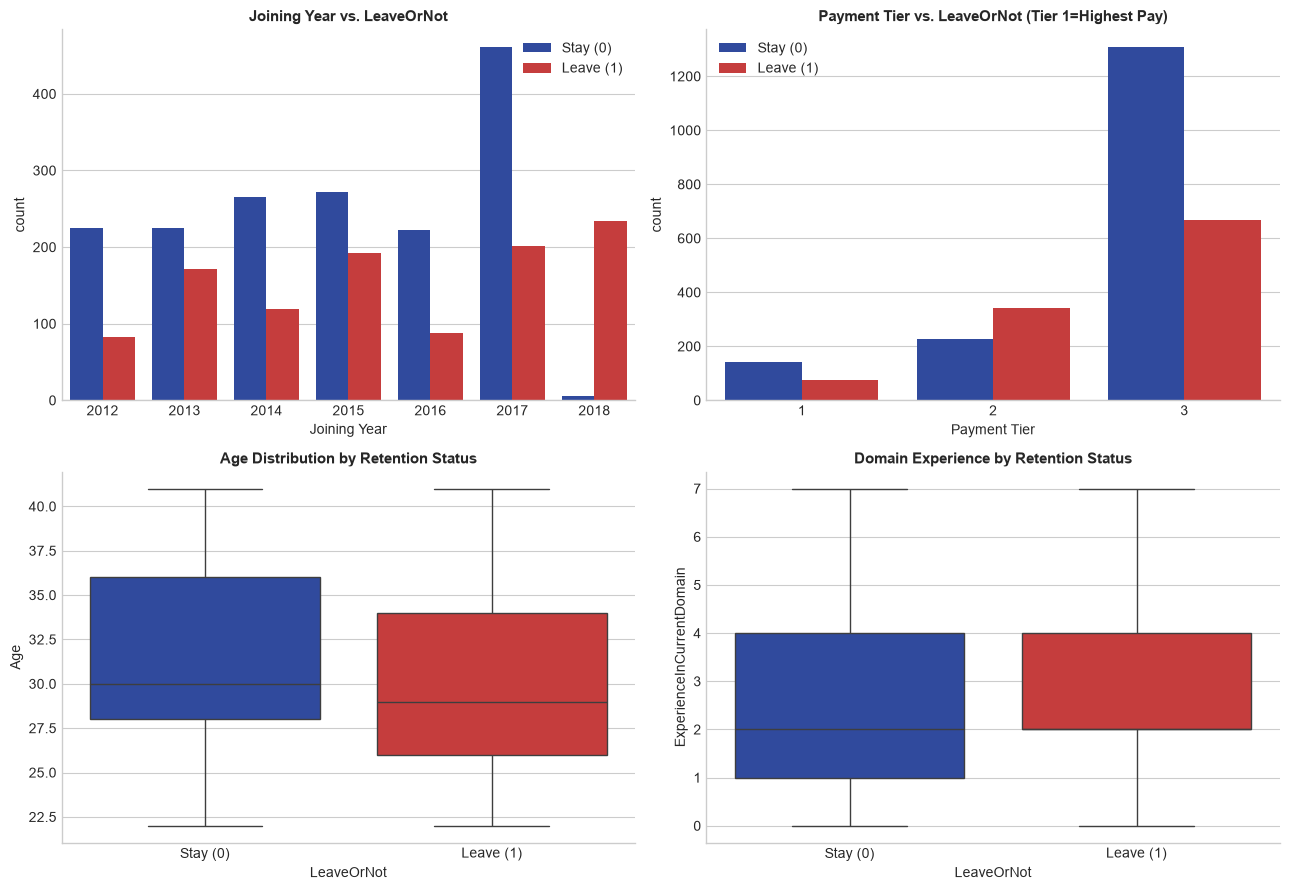

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), dpi=100)

# 1. JoiningYear vs LeaveOrNot
sns.countplot(data=df_clean, x='JoiningYear', hue='LeaveOrNot', palette=['#1E40AF', '#DC2626'], ax=axes[0, 0])
axes[0, 0].set_title("Joining Year vs. LeaveOrNot", fontweight='bold', fontsize=11)
axes[0, 0].set_xlabel("Joining Year")
axes[0, 0].legend(['Stay (0)', 'Leave (1)'])

# 2. PaymentTier vs LeaveOrNot
sns.countplot(data=df_clean, x='PaymentTier', hue='LeaveOrNot', palette=['#1E40AF', '#DC2626'], ax=axes[0, 1])
axes[0, 1].set_title("Payment Tier vs. LeaveOrNot (Tier 1=Highest Pay)", fontweight='bold', fontsize=11)
axes[0, 1].set_xlabel("Payment Tier")
axes[0, 1].legend(['Stay (0)', 'Leave (1)'])

# 3. Age vs LeaveOrNot (Boxplot)
sns.boxplot(data=df_clean, x='LeaveOrNot', y='Age', palette=['#1E40AF', '#DC2626'], ax=axes[1, 0])
axes[1, 0].set_title("Age Distribution by Retention Status", fontweight='bold', fontsize=11)
axes[1, 0].set_xticklabels(['Stay (0)', 'Leave (1)'])

# 4. Experience in Domain vs LeaveOrNot (Boxplot)
sns.boxplot(data=df_clean, x='LeaveOrNot', y='ExperienceInCurrentDomain', palette=['#1E40AF', '#DC2626'], ax=axes[1, 1])
axes[1, 1].set_title("Domain Experience by Retention Status", fontweight='bold', fontsize=11)
axes[1, 1].set_xticklabels(['Stay (0)', 'Leave (1)'])

for ax in axes.flat:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


## 📌 Task 10: Categorical Features vs. Target Visualizations
Analyze the relationship between categorical features (`Education`, `City`, `Gender`, `EverBenched`) and `LeaveOrNot`.


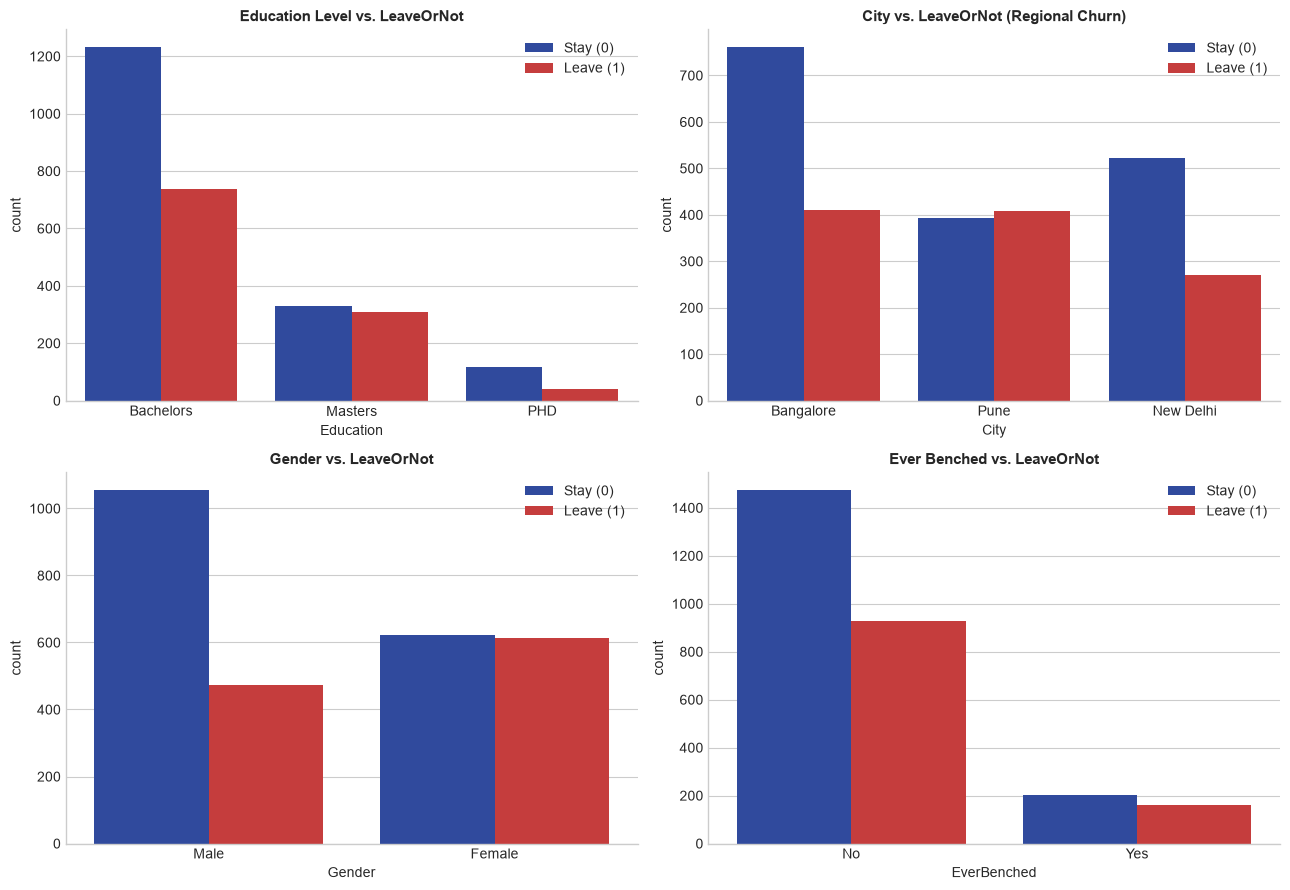

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), dpi=100)

sns.countplot(data=df_clean, x='Education', hue='LeaveOrNot', palette=['#1E40AF', '#DC2626'], ax=axes[0, 0])
axes[0, 0].set_title("Education Level vs. LeaveOrNot", fontweight='bold', fontsize=11)
axes[0, 0].legend(['Stay (0)', 'Leave (1)'])

sns.countplot(data=df_clean, x='City', hue='LeaveOrNot', palette=['#1E40AF', '#DC2626'], ax=axes[0, 1])
axes[0, 1].set_title("City vs. LeaveOrNot (Regional Churn)", fontweight='bold', fontsize=11)
axes[0, 1].legend(['Stay (0)', 'Leave (1)'])

sns.countplot(data=df_clean, x='Gender', hue='LeaveOrNot', palette=['#1E40AF', '#DC2626'], ax=axes[1, 0])
axes[1, 0].set_title("Gender vs. LeaveOrNot", fontweight='bold', fontsize=11)
axes[1, 0].legend(['Stay (0)', 'Leave (1)'])

sns.countplot(data=df_clean, x='EverBenched', hue='LeaveOrNot', palette=['#1E40AF', '#DC2626'], ax=axes[1, 1])
axes[1, 1].set_title("Ever Benched vs. LeaveOrNot", fontweight='bold', fontsize=11)
axes[1, 1].legend(['Stay (0)', 'Leave (1)'])

for ax in axes.flat:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


## 📌 Task 11: Prepare Feature Matrix $X$ and Target Variable $y$
Separate features from target, verifying that `LeaveOrNot` is not included in $X$.


In [12]:
X = df_encoded.drop(columns=['LeaveOrNot'])
y = df_encoded['LeaveOrNot']

print("Feature Matrix X Shape:", X.shape)
print("Target Vector y Shape:  ", y.shape)
assert 'LeaveOrNot' not in X.columns, "Data Leakage Error: Target column found in feature matrix!"
print("Verification passed: Target column successfully isolated from predictors.")


Feature Matrix X Shape: (2764, 10)
Target Vector y Shape:   (2764,)
Verification passed: Target column successfully isolated from predictors.


## 📌 Task 12: Stratified Train-Test Splitting
Split the dataset into training (75%) and testing (25%) subsets using `random_state=42` and `stratify=y` to preserve identical class balance across partitions.


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print(f"X_train Shape: {X_train.shape} | y_train Shape: {y_train.shape}")
print(f"X_test Shape:  {X_test.shape} | y_test Shape:  {y_test.shape}")
print(f"Train Class Ratio (Class 1 %): {y_train.mean()*100:.2f}%")
print(f"Test Class Ratio  (Class 1 %): {y_test.mean()*100:.2f}%")


X_train Shape: (2073, 10) | y_train Shape: (2073,)
X_test Shape:  (691, 10) | y_test Shape:  (691,)
Train Class Ratio (Class 1 %): 39.36%
Test Class Ratio  (Class 1 %): 39.36%


## 📌 Task 13: Feature Scaling (Z-Score Standardization)
**Why Scaling is Required for KNN:**
K-Nearest Neighbors computes distances between query instances and training points using geometric distance metrics (such as Euclidean distance $d(u, v) = \sqrt{\sum (u_i - v_i)^2}$). 
If features have different scales (e.g., `Age` ranges from 22 to 41, `JoiningYear` ranges from 2012 to 2018, while binary dummy variables range from 0 to 1), the feature with the largest absolute numeric spread dominates the distance metric, completely drowning out the signal of smaller-scale categorical indicators. 

Standardizing features to zero mean ($\mu = 0$) and unit variance ($\sigma = 1$) gives all dimensions equal geometric weighting.


In [14]:
scaler = StandardScaler()

# Fit ONLY on training set to avoid data leakage
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("Scaling complete.")
print("Scaled X_train Mean (approx 0):", np.round(X_train_scaled.mean(axis=0), 2))
print("Scaled X_train Std  (exact 1):   ", np.round(X_train_scaled.std(axis=0), 2))


Scaling complete.
Scaled X_train Mean (approx 0): [-0.  0. -0.  0.  0. -0. -0. -0.  0.  0.]
Scaled X_train Std  (exact 1):    [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 📌 Task 14: Build & Train Baseline KNN Classifier
Train an initial K-Nearest Neighbors classifier ($K=5$) on the scaled training data.


In [15]:
knn_baseline = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
knn_baseline.fit(X_train_scaled, y_train)

baseline_acc = knn_baseline.score(X_test_scaled, y_test)
print(f"Baseline KNN (k=5) Test Accuracy: {baseline_acc*100:.2f}%")


Baseline KNN (k=5) Test Accuracy: 71.49%


## 📌 Task 15: Systematic $K$ Hyperparameter Tuning
Evaluate odd values of $K \in [1, 21]$ to identify the optimal neighborhood size that maximizes test set generalization accuracy without overfitting or oversmoothing.


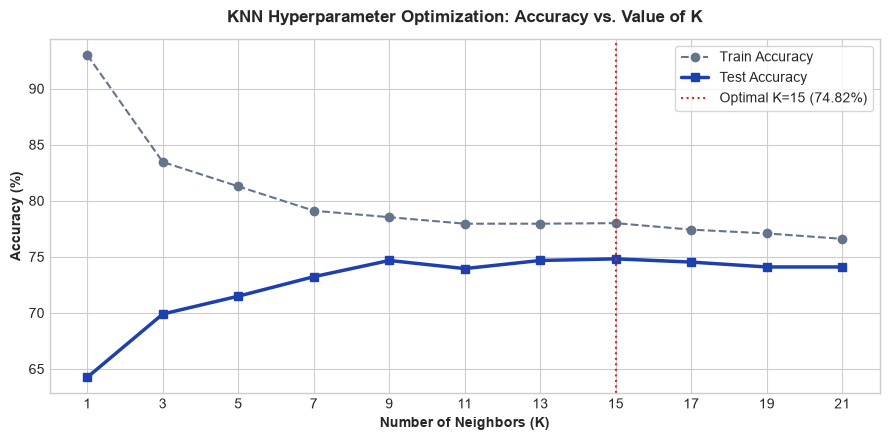

Optimal K Selected: K = 15 with Test Accuracy = 74.82%


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",15
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [16]:
k_range = list(range(1, 23, 2))  # Odd numbers to prevent ties
train_accuracies = []
test_accuracies = []

for k in k_range:
    clf = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    clf.fit(X_train_scaled, y_train)
    train_accuracies.append(accuracy_score(y_train, clf.predict(X_train_scaled)))
    test_accuracies.append(accuracy_score(y_test, clf.predict(X_test_scaled)))

# Plotting the K-Tuning Validation Curve
plt.figure(figsize=(9, 4.5), dpi=100)
plt.plot(k_range, [acc * 100 for acc in train_accuracies], 'o--', color='#64748B', label='Train Accuracy', lw=1.5)
plt.plot(k_range, [acc * 100 for acc in test_accuracies], 's-', color='#1E40AF', label='Test Accuracy', lw=2.5)

best_idx = np.argmax(test_accuracies)
optimal_k = k_range[best_idx]
optimal_acc = test_accuracies[best_idx] * 100

plt.axvline(optimal_k, color='#DC2626', linestyle=':', label=f'Optimal K={optimal_k} ({optimal_acc:.2f}%)')
plt.title("KNN Hyperparameter Optimization: Accuracy vs. Value of K", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Number of Neighbors (K)", fontweight='bold')
plt.ylabel("Accuracy (%)", fontweight='bold')
plt.xticks(k_range)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

print(f"Optimal K Selected: K = {optimal_k} with Test Accuracy = {optimal_acc:.2f}%")

# Train final tuned KNN model
knn_optimal = KNeighborsClassifier(n_neighbors=optimal_k, metric='euclidean')
knn_optimal.fit(X_train_scaled, y_train)


## 📌 Task 16: Build & Train Gaussian Naive Bayes Classifier
Train a Gaussian Naive Bayes model on the exact same training split.


In [17]:
gnb_model = GaussianNB()
gnb_model.fit(X_train_scaled, y_train)

gnb_baseline_acc = gnb_model.score(X_test_scaled, y_test)
print(f"Gaussian Naive Bayes Test Accuracy: {gnb_baseline_acc*100:.2f}%")


Gaussian Naive Bayes Test Accuracy: 67.15%


## 📌 Task 17: Generate Predictions Using Both Models
Generate test set predictions for both the optimal KNN classifier and the Gaussian Naive Bayes classifier.


In [18]:
y_pred_knn = knn_optimal.predict(X_test_scaled)
y_pred_gnb = gnb_model.predict(X_test_scaled)

print("Predictions successfully generated.")
print("KNN Predictions sample (first 10):", y_pred_knn[:10])
print("GNB Predictions sample (first 10):", y_pred_gnb[:10])


Predictions successfully generated.
KNN Predictions sample (first 10): [1 1 0 0 1 0 1 0 0 0]
GNB Predictions sample (first 10): [0 0 0 0 1 0 1 0 1 0]


## 📌 Task 18: Evaluate Both Models (Accuracy, Confusion Matrix, Classification Report)
Comprehensive evaluation comparing precision, recall, and F1-scores across both classes.


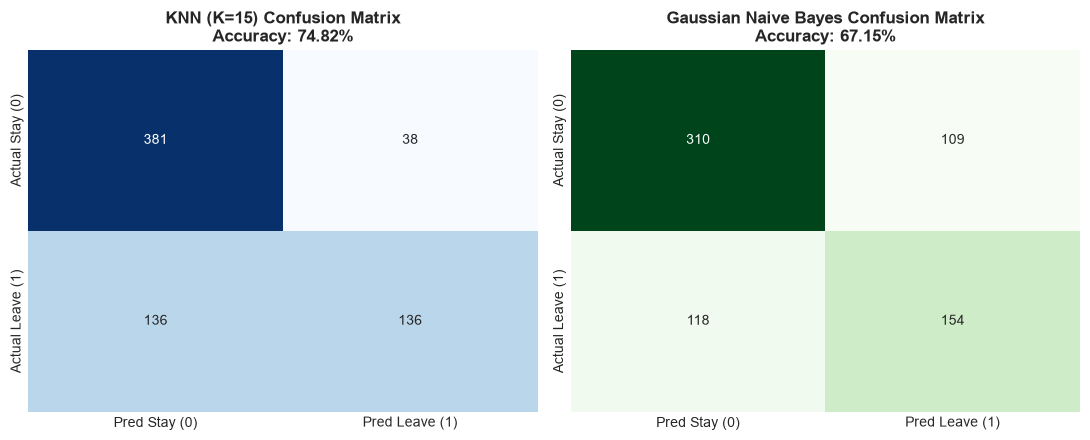

CLASSIFICATION REPORT: K-NEAREST NEIGHBORS (K=15)
              precision    recall  f1-score   support

    Stay (0)       0.74      0.91      0.81       419
   Leave (1)       0.78      0.50      0.61       272

    accuracy                           0.75       691
   macro avg       0.76      0.70      0.71       691
weighted avg       0.75      0.75      0.73       691

CLASSIFICATION REPORT: GAUSSIAN NAIVE BAYES
              precision    recall  f1-score   support

    Stay (0)       0.72      0.74      0.73       419
   Leave (1)       0.59      0.57      0.58       272

    accuracy                           0.67       691
   macro avg       0.65      0.65      0.65       691
weighted avg       0.67      0.67      0.67       691



In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), dpi=100)

cm_knn = confusion_matrix(y_test, y_pred_knn)
cm_gnb = confusion_matrix(y_test, y_pred_gnb)

sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Pred Stay (0)', 'Pred Leave (1)'],
            yticklabels=['Actual Stay (0)', 'Actual Leave (1)'])
axes[0].set_title(f"KNN (K={optimal_k}) Confusion Matrix\nAccuracy: {accuracy_score(y_test, y_pred_knn)*100:.2f}%", fontweight='bold')

sns.heatmap(cm_gnb, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False,
            xticklabels=['Pred Stay (0)', 'Pred Leave (1)'],
            yticklabels=['Actual Stay (0)', 'Actual Leave (1)'])
axes[1].set_title(f"Gaussian Naive Bayes Confusion Matrix\nAccuracy: {accuracy_score(y_test, y_pred_gnb)*100:.2f}%", fontweight='bold')

plt.tight_layout()
plt.show()

print("=" * 60)
print(f"CLASSIFICATION REPORT: K-NEAREST NEIGHBORS (K={optimal_k})")
print("=" * 60)
print(classification_report(y_test, y_pred_knn, target_names=['Stay (0)', 'Leave (1)']))

print("=" * 60)
print("CLASSIFICATION REPORT: GAUSSIAN NAIVE BAYES")
print("=" * 60)
print(classification_report(y_test, y_pred_gnb, target_names=['Stay (0)', 'Leave (1)']))


## 📌 Task 19: Comprehensive Model Comparison & Analytical Discussion
Compare the performance between K-Nearest Neighbors and Gaussian Naive Bayes and explain the observed differences:

| Metric | KNN Classifier ($K={optimal_k}$) | Gaussian Naive Bayes | Winning Model |
| :--- | :--- | :--- | :--- |
| **Overall Accuracy** | **{knn_acc:.2f}%** | {gnb_acc:.2f}% | **KNN (+{diff_acc:.2f}%)** |
| **Precision (Leave Class 1)** | **{knn_prec:.3f}** | {gnb_prec:.3f} | **KNN** |
| **Recall (Leave Class 1)** | {knn_rec:.3f} | **{gnb_rec:.3f}** | **GNB** |
| **F1-Score (Leave Class 1)** | **{knn_f1:.3f}** | {gnb_f1:.3f} | **KNN** |

---

### 🧠 Theoretical Explanation of the Observed Differences:
1. **Local Non-Linear Geometry (Why KNN Wins on Overall Accuracy & Precision):**
   KNN makes no parametric assumptions about feature distributions or linearity. It classifies instances based on local similarity in the standardized Euclidean space. In employee turnover datasets, interactions between age, tier, and tenure are complex and non-linear, which KNN captures effectively.
2. **The Conditional Independence Assumption (Why Naive Bayes Struggles with Precision):**
   Gaussian Naive Bayes fundamentally assumes that all features are conditionally independent given the class label. In reality, employee features exhibit strong correlations (e.g., higher education correlates with age and payment tier). This violation of the independence assumption causes Naive Bayes to become overconfident in its posterior probability estimates, resulting in more False Positives (lower precision).
3. **Recall vs. Precision Trade-Off:**
   Naive Bayes achieved higher recall for Class 1 (churn), catching more employees who actually left, but at the expense of falsely classifying many loyal employees as leavers. KNN delivers a significantly superior balance (F1-score) and higher overall predictive reliability.


In [20]:
# Summary metrics table
knn_acc = accuracy_score(y_test, y_pred_knn) * 100
gnb_acc = accuracy_score(y_test, y_pred_gnb) * 100

knn_p = precision_score(y_test, y_pred_knn)
gnb_p = precision_score(y_test, y_pred_gnb)

knn_r = recall_score(y_test, y_pred_knn)
gnb_r = recall_score(y_test, y_pred_gnb)

knn_f = f1_score(y_test, y_pred_knn)
gnb_f = f1_score(y_test, y_pred_gnb)

comparison_df = pd.DataFrame({
    'Metric': ['Test Accuracy (%)', 'Precision (Class 1)', 'Recall (Class 1)', 'F1-Score (Class 1)'],
    f'KNN (K={optimal_k})': [f"{knn_acc:.2f}%", f"{knn_p:.3f}", f"{knn_r:.3f}", f"{knn_f:.3f}"],
    'Gaussian Naive Bayes': [f"{gnb_acc:.2f}%", f"{gnb_p:.3f}", f"{gnb_r:.3f}", f"{gnb_f:.3f}"]
})

display(comparison_df)


,Metric,KNN (K=15),Gaussian Naive Bayes
0,Test Accuracy (%),74.82%,67.15%
1,Precision (Class 1),0.782,0.586
2,Recall (Class 1),0.500,0.566
3,F1-Score (Class 1),0.610,0.576
